# GitHub Flow와 PR 리뷰

**이 노트북에서 할 일**

1. 임시 폴더에 팀 원격 저장소 하나와 작성자·리뷰어 저장소 두 개를 만듭니다.
2. 기능 브랜치에 커밋을 쌓아 원격에 올리고, PR로 볼 변경 범위와 설명을 만듭니다.
3. 리뷰에서 찾은 빈 값 결함을 고치고, 병합한 main을 원격까지 올립니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다. 01절에서 쓴 Git이 필요합니다.

**강의와 실습 범위** — 강의 시간에는 6~8번과 11~12번 소제목을 설명합니다.
6~8번은 기능 브랜치·올리기·PR 범위이고, 11~12번은 리뷰와 병합입니다.
1~5번과 9~10번은 셀을 함께 실행하고, 결과 읽기는 실습 시간에 이어서 읽습니다.

실습 폴더 `labs/part1/ch03-git-github`에서 `uv sync --locked`로 만든 `.venv`를 커널로 고릅니다.
첫 셀부터 순서대로 실행합니다. GitHub 계정과 네트워크는 쓰지 않습니다.
팀 원격 저장소도 임시 폴더 안에 만들므로, 실제 PR 화면은 이 노트북에 나오지 않습니다.

## 오늘 볼 그림

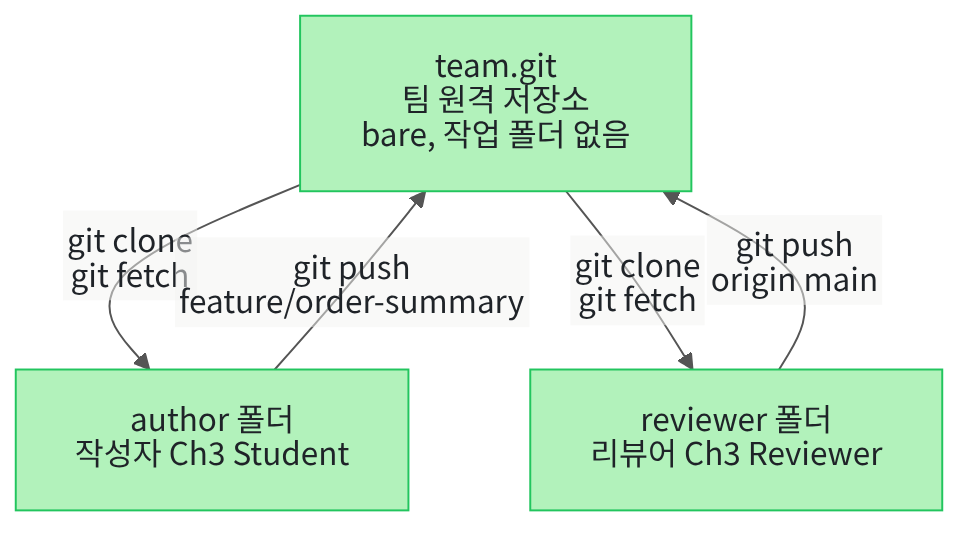

위 가운데 상자가 팀이 함께 쓰는 원격 저장소이고, 아래 왼쪽은 작성자, 아래 오른쪽은 리뷰어의 저장소입니다.
아래로 가는 화살표는 받아 오는 명령, 위로 가는 화살표는 올리는 명령입니다.
작성자와 리뷰어는 서로 직접 주고받지 않고, 늘 원격 저장소를 거칩니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 01절처럼 빈 임시 폴더를 만들고 그 폴더로 작업 위치를 옮깁니다.
이번에는 그 안에 저장소 폴더 세 개를 만듭니다. 폴더 이름의 앞머리만 `ch03-02-`로 바꿨습니다.

In [1]:
# 저장소 세 개를 담을 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-02-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.

## 2. git 명령 함수에 폴더 더하기

01절의 `run_git()` 함수는 현재 작업 폴더에서만 git 명령을 실행했습니다. 이번 절은 저장소 세 개를 오가며 명령을 실행합니다.
그래서 같은 이름으로 함수를 다시 정의하고, 명령을 실행할 폴더를 받는 매개변수 `folder`를 더합니다.

- 매개변수 `folder`의 기본값은 `"."`입니다. 점 하나는 현재 작업 폴더를 뜻합니다. 기본값 매개변수는 Ch 2 04절에서 배웠습니다.
- 함수 `subprocess.run()`에 인자 `cwd=folder`를 더합니다. Ch 1 05절에서 쓴 인자로, 명령을 실행할 폴더를 정합니다.
- 출력 첫 줄에는 폴더 이름을 붙여 `author $ git push`처럼 보여 줍니다. 어느 저장소에서 실행한 명령인지 바로 읽을 수 있습니다.

나머지 줄은 01절과 같습니다. 같은 이름으로 다시 정의하면 뒤의 셀은 새 함수를 씁니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# git 명령을 폴더 하나에서 실행하고, 폴더 이름과 명령, 출력을 함께 보여 주는 함수
import shlex
import subprocess


def run_git(command: str, folder: str = "."):
    full_command = "git " + command
    # split()은 따옴표로 묶은 메시지를 공백이 있어도 한 낱말로 둡니다
    arguments = shlex.split(full_command)
    # cwd 인자에 적은 폴더에서 명령을 실행하고, 글자는 UTF-8 규칙으로 읽습니다
    result = subprocess.run(arguments, capture_output=True, encoding="utf-8", cwd=folder)
    print(folder, "$", full_command)
    print(result.stdout + result.stderr)
    # 종료 코드가 0이 아닐 때만 숫자를 보여 줍니다
    if result.returncode != 0:
        print("종료 코드:", result.returncode)

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 새로 정의하기만 했습니다.

## 3. 팀이 함께 쓰는 원격 저장소 만들기

여러 사람이 같은 코드를 고치려면 모두가 커밋을 올리고 받아 오는 저장소가 하나 필요합니다.
이런 저장소를 원격 저장소(remote repository)라고 부릅니다. 실무에서는 GitHub 서버의 저장소가 이 역할을 합니다.
이 노트북은 네트워크를 쓰지 않고, 임시 폴더 안의 `team.git` 폴더를 원격 저장소로 씁니다.

옵션 `--bare`는 작업 폴더 없이 커밋 기록만 담는 저장소를 만듭니다. 이런 저장소를 bare 저장소라고 부릅니다.
아무도 이 폴더에서 파일을 직접 고치지 않으므로 작업 폴더가 필요 없습니다. 옵션 `-b main`은 01절처럼 첫 브랜치 이름을 정합니다.

실행 전에 예상합니다. 빈 저장소를 만들었다는 줄이 나오고, 작업 폴더에 `team.git` 폴더가 생길 것입니다.

In [3]:
# 팀 원격 저장소로 쓸 bare 저장소를 만들고, 작업 폴더의 파일을 봅니다
run_git("init --bare -b main team.git")
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

. $ git init --bare -b main team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git/

현재 작업 폴더의 파일: ['team.git']


**결과 읽기** — 첫 줄 `. $ git init --bare -b main team.git`의 점은 현재 작업 폴더에서 실행했다는 표시입니다.
둘째 줄 `Initialized empty Git repository`는 빈 저장소를 만들었다는 뜻입니다. 파일 목록은 `['team.git']`입니다.
01절과 달리 경로가 `.git/`이 아니라 `team.git/`으로 끝납니다. bare 저장소는 폴더 자체가 기록을 담기 때문입니다.

## 4. 작성자가 원격 저장소 복제하기

작성자는 원격 저장소를 복제(clone)해 자기 저장소를 만듭니다. 명령 `git clone team.git author`는 기록을 받아 `author` 폴더를 만듭니다.
복제한 저장소에는 원격 저장소의 위치가 `origin`이라는 이름으로 적힙니다. 처음 복제한 원격에 붙이는 관례적인 이름입니다.
명령 `git remote -v`는 저장소에 적힌 원격 이름과 위치를 보여 줍니다.

복제한 뒤 작성자 정보는 01절처럼 이 저장소에만 적습니다. 함수의 두 번째 인자 `"author"`가 명령을 실행할 폴더입니다.
실행 전에 예상합니다. 원격 저장소가 비어 있으므로, 빈 저장소를 복제했다는 안내가 나올 것입니다.

In [4]:
# 원격 저장소를 author 폴더로 복제하고, 원격 이름을 본 뒤 작성자 정보를 이 저장소에만 적습니다
run_git("clone team.git author")
run_git("remote -v", "author")
run_git('config user.name "Ch3 Student"', "author")
run_git("config user.email student@example.com", "author")
run_git("config user.name", "author")

. $ git clone team.git author
Cloning into 'author'...
done.

author $ git remote -v
origin	[사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git (fetch)
origin	[사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git (push)

author $ git config user.name "Ch3 Student"

author $ git config user.email student@example.com

author $ git config user.name
Ch3 Student



**결과 읽기** — 줄 `Cloning into 'author'...`는 복제를 시작했다는 뜻입니다.
경고 `You appear to have cloned an empty repository`는 커밋이 없는 저장소를 복제했다는 안내이고, 종료 코드 줄은 없습니다.

둘째 명령의 출력에서 이름 `origin` 뒤의 경로가 원격 저장소의 위치입니다.
줄 끝의 `(fetch)`는 받아 올 때, `(push)`는 올릴 때 쓰는 위치입니다. 경로는 실행할 때마다 달라집니다.

뒤의 세 명령 줄 앞에도 `author $`가 붙어, 작성자 폴더에서 실행했음을 알 수 있습니다.
마지막 명령의 결과 `Ch3 Student`가 작성자 저장소에 저장된 이름입니다.

## 5. main에 첫 커밋을 만들어 원격에 올리기

팀 저장소의 출발점이 될 파일 두 개를 작성자가 만듭니다. 무시 규칙 파일 `.gitignore`에는 01절에서 쓴 `__pycache__/` 한 줄을 적습니다.

다른 파일 `pull_request_template.md`는 PR 설명의 빈 양식입니다. 풀 리퀘스트(PR)는 8번에서 자세히 설명합니다.
저장소에 이 이름의 파일이 있으면 GitHub가 PR 설명 칸에 양식을 채워 둡니다. 이번에 GitHub 화면에서는 확인하지 않았습니다.

파일 이름 앞의 `author/`는 Ch 1 02절에서 배운 상대 경로로, 작성자 폴더 안을 가리킵니다.
실행 전에 예상합니다. 두 파일이 main 브랜치의 첫 커밋에 들어갈 것입니다.

In [5]:
# 작성자 저장소에 무시 규칙과 PR 템플릿을 만들고 첫 커밋으로 기록합니다
template_text = """## 변경 내용
- (여기에 적기)

## 확인한 입력
- [ ] 빈 값을 넣어 실행
"""
with open("author/.gitignore", "w", encoding="utf-8") as file:
    file.write("__pycache__/\n")
with open("author/pull_request_template.md", "w", encoding="utf-8") as file:
    file.write(template_text)
run_git("add .gitignore pull_request_template.md", "author")
run_git('commit -m "chore: 저장소와 PR 템플릿 시작"', "author")

author $ git add .gitignore pull_request_template.md

author $ git commit -m "chore: 저장소와 PR 템플릿 시작"
[main (root-commit) e439789] chore: 저장소와 PR 템플릿 시작
 2 files changed, 6 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 pull_request_template.md



**결과 읽기** — 표시 `main (root-commit)`은 main 브랜치의 첫 커밋이라는 뜻입니다.
요약 줄 `2 files changed`로 두 파일이 함께 들어간 것을 확인합니다.

지금 이 커밋은 작성자 저장소에만 있습니다. 명령 `git push`는 내 저장소의 커밋을 원격 저장소로 올립니다.
명령 `git push -u origin main`은 main 브랜치를 원격 `origin`에 올린다는 뜻입니다.

옵션 `-u`는 내 main과 원격의 main을 짝으로 적어 둡니다. 그다음부터는 `git push`만 적어도 같은 짝으로 올립니다.
실행 전에 예상합니다. 원격 저장소에 main 브랜치가 새로 생겼다는 줄이 나올 것입니다.

In [6]:
# 작성자의 main 브랜치를 원격 저장소에 올리고 짝으로 적어 둡니다
run_git("push -u origin main", "author")

author $ git push -u origin main
Branch 'main' set up to track remote branch 'main' from 'origin'.
To [사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git
 * [new branch]      main -> main



**결과 읽기** — 표시 `[new branch]`는 원격 저장소에 브랜치가 새로 생겼다는 뜻입니다.
같은 줄의 `main -> main`은 내 main을 원격의 main으로 올렸다는 뜻입니다.
출력 첫 줄 `Branch 'main' set up to track`은 옵션 `-u`로 두 main을 짝으로 적었다는 안내입니다.

## 6. 기능 브랜치 만들기

브랜치(branch)는 커밋이 이어지는 줄기의 이름입니다. 01절에서는 main 브랜치 하나에만 커밋을 쌓았습니다.

작업 방식 GitHub Flow는 main을 늘 동작하는 상태로 두고, 새 작업은 따로 만든 브랜치에서 합니다.
이렇게 기능 하나를 만들려고 main에서 갈라 낸 브랜치를 기능 브랜치(feature branch)라고 부릅니다.

명령 `git switch -c feature/order-summary`는 지금 커밋에서 새 브랜치를 만들고 그 브랜치로 옮겨 갑니다.
옵션 `-c`는 새로 만들기(create)를 뜻합니다. 명령 `git branch`는 브랜치 목록을 보여 줍니다.
실행 전에 예상합니다. 목록에 브랜치 두 개가 나오고, 새 브랜치 앞에 표시가 붙을 것입니다.

In [7]:
# 작성자 저장소에서 기능 브랜치를 만들어 옮겨 가고, 브랜치 목록을 봅니다
run_git("switch -c feature/order-summary", "author")
run_git("branch", "author")

author $ git switch -c feature/order-summary
Switched to a new branch 'feature/order-summary'

author $ git branch
* feature/order-summary
  main



**결과 읽기** — 줄 `Switched to a new branch 'feature/order-summary'`는 새 브랜치로 옮겨 갔다는 뜻입니다.
목록의 `* feature/order-summary`에서 별표는 지금 있는 브랜치를 가리킵니다. 아래 줄의 `main`도 그대로 남아 있습니다.

기능 브랜치에 주문 요약 함수 파일 `summary.py`를 커밋합니다. 함수는 주문 건수를 받아 01절 `app.py`처럼 「주문 N건」 글을 반환합니다.
파일에 적는 글은 Ch 2 04절의 함수 정의이고, 매개변수 옆 `int`는 Ch 2 07절의 타입힌트입니다.

명령 `git branch -v`는 브랜치마다 가리키는 커밋의 메시지도 함께 보여 줍니다.
실행 전에 예상합니다. 기능 브랜치만 새 커밋을 가리키고, main은 첫 커밋에 남을 것입니다.

In [8]:
# 기능 브랜치에 주문 요약 함수 파일을 커밋하고, 브랜치마다 가리키는 커밋을 봅니다
summary_text = """def summarize(count: int) -> str:
    return f"주문 {count}건"
"""
with open("author/summary.py", "w", encoding="utf-8") as file:
    file.write(summary_text)
run_git("add summary.py", "author")
run_git('commit -m "feat: 주문 요약 함수 추가"', "author")
run_git("branch -v", "author")

author $ git add summary.py

author $ git commit -m "feat: 주문 요약 함수 추가"
[feature/order-summary 2d95a9b] feat: 주문 요약 함수 추가
 1 file changed, 2 insertions(+)
 create mode 100644 summary.py

author $ git branch -v
* feature/order-summary 2d95a9b feat: 주문 요약 함수 추가
  main                  e439789 chore: 저장소와 PR 템플릿 시작



**결과 읽기** — 커밋 요약 줄은 `1 file changed, 2 insertions(+)`입니다.
브랜치 목록에서 기능 브랜치는 `feat: 주문 요약 함수 추가` 커밋을 가리킵니다. main 브랜치는 `chore: 저장소와 PR 템플릿 시작` 커밋에 남았습니다.
새 커밋을 만들면 지금 있는 브랜치만 앞으로 옮겨 갑니다.

## 7. 기능 브랜치를 원격 저장소에 올리기

기능 브랜치도 원격 저장소에 올려야 다른 사람이 볼 수 있습니다. main 브랜치를 올릴 때처럼 옵션 `-u`로 짝을 적습니다.
명령 `git branch -vv`는 브랜치마다 짝이 된 원격 브랜치의 이름을 대괄호 안에 보여 줍니다.

실행 전에 예상합니다. 두 브랜치 모두 대괄호 안에 `origin/`으로 시작하는 이름이 나올 것입니다.

In [9]:
# 기능 브랜치를 원격에 올리고, 브랜치마다 짝이 된 원격 브랜치를 봅니다
run_git("push -u origin feature/order-summary", "author")
run_git("branch -vv", "author")

author $ git push -u origin feature/order-summary
Branch 'feature/order-summary' set up to track remote branch 'feature/order-summary' from 'origin'.
To [사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git
 * [new branch]      feature/order-summary -> feature/order-summary

author $ git branch -vv
* feature/order-summary 2d95a9b [origin/feature/order-summary] feat: 주문 요약 함수 추가
  main                  e439789 [origin/main] chore: 저장소와 PR 템플릿 시작



**결과 읽기** — 표시 `[new branch]`로 원격에 기능 브랜치가 생긴 것을 확인합니다.
목록의 `[origin/feature/order-summary]`와 `[origin/main]`이 짝이 된 원격 브랜치의 이름입니다.

이름 `origin/main`은 작성자 저장소가 마지막으로 확인한 원격 main의 위치입니다. 원격 저장소를 매번 새로 읽는 이름은 아닙니다.

## 8. PR로 볼 변경 범위와 설명 만들기

풀 리퀘스트(pull request, PR)는 내 브랜치의 변경을 main에 합쳐 달라고 요청하는 GitHub 기능입니다.
PR 화면에는 바뀐 파일, 설명 글, 리뷰 의견이 한곳에 모입니다.
이 노트북은 GitHub를 쓰지 않으므로, PR 화면에 나올 변경 범위와 설명 글을 직접 만듭니다.

명령 `git diff --stat origin/main...HEAD`는 원격 main과 지금 브랜치를 비교합니다.
점 세 개 `...`는 두 브랜치가 갈라진 커밋 뒤로 지금 브랜치에 더해진 변경만 보라는 뜻입니다. 옵션 `--stat`은 파일별 줄 수만 보여 줍니다.

실행 전에 예상합니다. 이번 기능 브랜치에서 더한 `summary.py` 한 파일만 나올 것입니다.

In [10]:
# PR에 나올 변경 범위를 파일별 줄 수로 요약합니다
run_git("diff --stat origin/main...HEAD", "author")

author $ git diff --stat origin/main...HEAD
 summary.py | 2 ++
 1 file changed, 2 insertions(+)



**결과 읽기** — 줄 `summary.py | 2 ++`는 이 파일에 두 줄이 더해졌다는 뜻입니다. 요약 줄은 `1 file changed, 2 insertions(+)`입니다.
첫 커밋에 있던 두 파일은 이번 범위에 들어가지 않았습니다.

PR 설명은 저장소에 있는 템플릿을 채워 씁니다. 템플릿 파일을 읽기 모드 `"r"`로 열어 글을 읽고, 빈칸 `(여기에 적기)`를 바꿉니다.
글의 메서드 `replace()`는 Ch 1 04절에서 쓴 메서드로, 앞 글을 뒤 글로 바꾼 새 글을 반환합니다.

확인 칸 `- [ ] 빈 값을 넣어 실행`은 작성자가 아직 해 보지 않아 그대로 둡니다. 대괄호 안에 x를 적으면 확인했다는 표시입니다.
실행 전에 예상합니다. 변경 내용 칸만 채워지고, 확인 칸은 빈 대괄호로 남을 것입니다.

In [11]:
# 저장소의 PR 템플릿을 읽고, 변경 내용 칸을 채워 PR 설명 글을 만듭니다
with open("author/pull_request_template.md", "r", encoding="utf-8") as file:
    saved_template = file.read()
pr_text = saved_template.replace("(여기에 적기)", "주문 건수를 글로 만드는 summarize() 함수 추가")
print("PR 설명 글:")
print(pr_text)

PR 설명 글:
## 변경 내용
- 주문 건수를 글로 만드는 summarize() 함수 추가

## 확인한 입력
- [ ] 빈 값을 넣어 실행



**결과 읽기** — 줄 `- 주문 건수를 글로 만드는 summarize() 함수 추가`가 채워진 변경 내용입니다.
확인 칸은 `- [ ] 빈 값을 넣어 실행`으로 비어 있습니다.
실제 GitHub에서는 이 글을 PR 설명 칸에 적습니다. 이번에는 PR 화면을 만들지 않았습니다.

## 9. 리뷰어가 원격 저장소 복제하기

코드 리뷰(code review)는 작성자가 아닌 사람이 변경을 읽고 실행해 보며 문제를 찾는 일입니다.
리뷰어는 자기 저장소를 따로 복제해 기능 브랜치를 확인합니다. 병합 커밋도 만들 것이므로 리뷰어 정보를 적습니다.
이름은 작성자와 같은 규칙으로 `Ch3 Reviewer`를 씁니다.

복제한 뒤 폴더의 파일 목록도 봅니다. 목록 순서는 컴퓨터마다 다를 수 있어 Ch 2 03절의 `sorted()`로 정렬합니다.
실행 전에 예상합니다. 원격에 커밋이 있으니 경고 없이 복제되고, 목록에 `summary.py`는 없을 것입니다.

In [12]:
# 원격 저장소를 reviewer 폴더로 복제하고, 리뷰어 정보를 적은 뒤 파일 목록을 봅니다
run_git("clone team.git reviewer")
run_git('config user.name "Ch3 Reviewer"', "reviewer")
run_git("config user.email reviewer@example.com", "reviewer")
file_names = os.listdir("reviewer")
print("reviewer 폴더의 파일:", sorted(file_names))

. $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

reviewer $ git config user.name "Ch3 Reviewer"

reviewer $ git config user.email reviewer@example.com

reviewer 폴더의 파일: ['.git', '.gitignore', 'pull_request_template.md']


**결과 읽기** — 복제 출력에는 빈 저장소 경고가 없습니다. 파일 목록은 `['.git', '.gitignore', 'pull_request_template.md']`입니다.
복제한 저장소는 원격의 main 브랜치로 시작합니다. 그래서 기능 브랜치에만 있는 `summary.py`는 보이지 않습니다.

## 10. 값 하나 바꿔 보기 — 브랜치를 main에서 기능 브랜치로

같은 리뷰어 폴더에서 브랜치 하나만 바꿔 파일 목록을 다시 봅니다. 명령 `git switch feature/order-summary`는 그 브랜치로 옮겨 갑니다.
리뷰어 저장소에는 아직 이 이름의 브랜치가 없습니다. 이럴 때 원격에 같은 이름이 있으면, 그 원격 브랜치와 짝인 브랜치를 새로 만듭니다.

실행 전에 예상합니다. 옮겨 간 뒤에는 목록에 `summary.py`가 더해질 것입니다.

In [13]:
# 리뷰어 저장소를 기능 브랜치로 옮기고, 파일 목록을 다시 봅니다
run_git("switch feature/order-summary", "reviewer")
file_names = os.listdir("reviewer")
print("reviewer 폴더의 파일:", sorted(file_names))

reviewer $ git switch feature/order-summary
Branch 'feature/order-summary' set up to track remote branch 'feature/order-summary' from 'origin'.
Switched to a new branch 'feature/order-summary'

reviewer 폴더의 파일: ['.git', '.gitignore', 'pull_request_template.md', 'summary.py']


**결과 읽기** — 줄 `set up to track remote branch`는 원격 브랜치와 짝인 브랜치를 새로 만들었다는 안내입니다.
파일 목록 끝에 `'summary.py'`가 더해졌습니다. 같은 폴더라도 브랜치를 옮기면 작업 폴더의 파일이 바뀝니다.

## 11. Before — 리뷰어가 기능 브랜치를 읽고 실행하기

리뷰어는 줄 수 요약보다 실제로 바뀐 줄을 먼저 읽습니다. 옵션 `--stat` 없이 같은 범위를 비교합니다.
실행 전에 예상합니다. 더하기(+) 줄 두 개로 된 함수가 나올 것입니다.

In [14]:
# Before: 리뷰어가 기능 브랜치에서 더해진 줄을 읽습니다
run_git("diff origin/main...HEAD", "reviewer")

reviewer $ git diff origin/main...HEAD
diff --git a/summary.py b/summary.py
new file mode 100644
index 0000000..25319f7
--- /dev/null
+++ b/summary.py
@@ -0,0 +1,2 @@
+def summarize(count: int) -> str:
+    return f"주문 {count}건"



**결과 읽기** — 더하기 줄 `+def summarize(count: int) -> str:`와 `+    return f"주문 {count}건"`이 기능 브랜치가 더한 전부입니다.
타입힌트 `int`가 있어도 Ch 2 07절에서 본 것처럼 값을 검사하지는 않습니다.
PR 설명의 빈 값 확인 칸도 비어 있었으므로, 리뷰어가 직접 실행해 봅니다.

확인 파일을 새 Python으로 실행하는 함수 `run_python()`을 만듭니다. 뼈대는 Ch 2 08절 `run_pytest()`와 같습니다.
목록 첫 칸 `sys.executable`은 지금 노트북을 실행하는 Python 프로그램의 경로이고, 둘째 칸이 실행할 파일 이름입니다.
인자 `cwd=folder`로 실행할 폴더를 정합니다.

글자는 Ch 2 08절처럼 인자 `text=True`로 받습니다. 새로 실행한 Python은 컴퓨터의 기본 규칙으로 글자를 내보내므로, 받는 쪽도 같은 규칙으로 읽습니다.
출력을 보여 주는 네 줄은 `run_git()`과 같습니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [15]:
# 폴더 하나에서 Python 파일을 실행하고, 출력과 종료 코드를 보여 주는 함수
import sys


def run_python(file_name: str, folder: str):
    arguments = [sys.executable, file_name]
    # 출력을 모아 두고, Ch 2 08절처럼 글로 받습니다
    result = subprocess.run(arguments, capture_output=True, text=True, cwd=folder)
    print(folder, "$ python", file_name)
    print(result.stdout + result.stderr)
    if result.returncode != 0:
        print("종료 코드:", result.returncode)

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 만들기만 했습니다.

리뷰어가 확인 파일 `check_summary.py`를 자기 폴더에 만듭니다. 이 파일은 함수에 보통 값 3과 빈 글자 `""`를 차례로 넣습니다.
첫 줄은 Ch 2 07절의 `from … import` 문으로, 같은 폴더의 `summary.py`에서 함수를 불러옵니다.

빈 글자 쪽은 Ch 2 05절처럼 `try`와 `except ValueError`로 감쌉니다. 숫자로 바꿀 수 없다는 오류가 나면 멈추지 않고 내용을 출력합니다.
확인 파일은 리뷰어만 쓰는 파일이라 커밋하지 않습니다.
실행 전에 예상합니다. 빈 글자를 넣으면 건수가 비어 있는 글이 나올 것입니다.

In [16]:
# Before: 보통 값과 빈 글자를 넣어 보는 확인 파일을 만들고 기능 브랜치에서 실행합니다
check_text = """from summary import summarize

print("보통 값 3:", summarize(3))
try:
    print("빈 값:", summarize(""))
except ValueError as error:
    print("입력 오류:", error)
"""
with open("reviewer/check_summary.py", "w", encoding="utf-8") as file:
    file.write(check_text)
run_python("check_summary.py", "reviewer")

reviewer $ python check_summary.py
보통 값 3: 주문 3건
빈 값: 주문 건



**결과 읽기** — 보통 값은 `보통 값 3: 주문 3건`으로 맞게 나왔습니다. 빈 글자는 오류 없이 `빈 값: 주문 건`이 나왔습니다.
건수가 빠진 틀린 글이 조용히 만들어졌고, 입력 오류 줄은 없습니다.

리뷰어는 PR에 이렇게 의견을 남깁니다. 「빈 글자를 넣으면 오류 없이 `주문 건`이 나옵니다. 숫자로 바꿀 수 없는 값은 오류로 알려 주세요.」
의견에는 넣은 값, 실제 결과, 기대하는 동작을 함께 적습니다. 그래야 작성자가 같은 결과를 다시 만들 수 있습니다.
이번에는 GitHub 화면에 의견을 적지 않았습니다.

## 12. After — 고친 커밋을 올리고 main에 병합하기

작성자는 리뷰 의견대로 함수를 고칩니다. 글을 만들기 전에 Ch 2 01절의 형 변환 `int()`로 건수를 정수로 바꿉니다.
빈 글자처럼 정수로 바꿀 수 없는 값이 오면 `int()`에서 `ValueError`가 납니다. Ch 2 05절처럼 틀린 값을 빈 결과로 감추지 않고 드러내는 방법입니다.

함수 `int()`는 숫자 모양 글 `"3"`도 정수 3으로 바꾸므로, 고친 함수는 그런 글도 받습니다. 이 경우는 이번에 실행하지 않았습니다.

고친 커밋은 같은 기능 브랜치에 쌓고 `git push`로 올립니다. 옵션 `-u`로 짝을 적어 두었으므로 원격과 브랜치 이름은 적지 않습니다.
실행 전에 예상합니다. 비교 결과에 빼기 줄 하나와 더하기 줄 세 개가 나올 것입니다.

In [17]:
# After: 작성자가 함수를 고쳐 커밋하고, 같은 기능 브랜치를 원격에 올립니다
fixed_text = """def summarize(count: int) -> str:
    # 정수로 바꿀 수 없는 값이면 ValueError가 납니다
    number = int(count)
    return f"주문 {number}건"
"""
with open("author/summary.py", "w", encoding="utf-8") as file:
    file.write(fixed_text)
run_git("diff", "author")
run_git("add summary.py", "author")
run_git('commit -m "fix: 빈 주문 건수 입력 확인"', "author")
run_git("push", "author")

author $ git diff
diff --git a/summary.py b/summary.py
index 25319f7..6c43abd 100644
--- a/summary.py
+++ b/summary.py
@@ -1,2 +1,4 @@
 def summarize(count: int) -> str:
-    return f"주문 {count}건"
+    # 정수로 바꿀 수 없는 값이면 ValueError가 납니다
+    number = int(count)
+    return f"주문 {number}건"

author $ git add summary.py

author $ git commit -m "fix: 빈 주문 건수 입력 확인"
[feature/order-summary e05b0df] fix: 빈 주문 건수 입력 확인
 1 file changed, 3 insertions(+), 1 deletion(-)

author $ git push
To [사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git
   2d95a9b..e05b0df  feature/order-summary -> feature/order-summary



**결과 읽기** — 비교 결과에서 `-    return f"주문 {count}건"` 줄이 빠지고 `+    number = int(count)` 줄이 더해졌습니다.
커밋 요약 줄은 `1 file changed, 3 insertions(+), 1 deletion(-)`입니다.
올리기 출력의 `feature/order-summary -> feature/order-summary`는 원격의 기능 브랜치가 새 커밋으로 옮겨 갔다는 뜻입니다.

리뷰어 저장소는 아직 고친 커밋을 모릅니다. 명령 `git fetch`는 원격 저장소의 새 커밋을 받아 오고, `origin/`으로 시작하는 이름만 옮깁니다.
내 브랜치는 옮기지 않으므로 작업 폴더의 파일도 그대로입니다.

받아 온 뒤 `git branch -vv`로 짝과 비교한 결과를 봅니다.
실행 전에 예상합니다. 리뷰어의 기능 브랜치가 원격보다 커밋 하나 뒤처졌다는 표시가 나올 것입니다.

In [18]:
# After: 리뷰어 저장소에서 원격의 새 커밋을 받아 오고, 짝과 비교한 결과를 봅니다
run_git("fetch", "reviewer")
run_git("branch -vv", "reviewer")

reviewer $ git fetch
From [사용자 폴더]/tmp/ch03-02-8hklh3oc/team
   2d95a9b..e05b0df  feature/order-summary -> origin/feature/order-summary

reviewer $ git branch -vv
* feature/order-summary 2d95a9b [origin/feature/order-summary: behind 1] feat: 주문 요약 함수 추가
  main                  e439789 [origin/main] chore: 저장소와 PR 템플릿 시작



**결과 읽기** — 받아 오기 출력의 `feature/order-summary -> origin/feature/order-summary`는 원격 이름 쪽만 새 커밋으로 옮겼다는 뜻입니다.
목록의 `behind 1`은 리뷰어의 기능 브랜치가 짝보다 커밋 1개 뒤라는 뜻입니다.

리뷰 의견이 반영됐으니 기능 브랜치를 main에 병합(merge)합니다. 병합은 두 브랜치의 커밋 줄기를 하나로 합치는 일입니다.
리뷰어는 main으로 옮긴 뒤 방금 받아 온 원격 이름 `origin/feature/order-summary`를 병합합니다. 리뷰어의 기능 브랜치는 한 커밋 뒤처져 있기 때문입니다.

옵션 `--no-ff`는 병합 커밋을 꼭 만들라는 뜻입니다. 병합 커밋(merge commit)은 부모 커밋이 둘인 커밋입니다.
이 옵션이 없으면 main 이름만 앞으로 옮기는 fast-forward 병합이 될 수 있습니다. 그 경우는 이번에 실행하지 않았습니다.

실행 전에 예상합니다. 병합 커밋이 만들어지고, main에 `summary.py`가 들어올 것입니다.

In [19]:
# After: 리뷰어가 main으로 옮겨 원격의 기능 브랜치를 병합 커밋으로 합칩니다
run_git("switch main", "reviewer")
run_git('merge --no-ff origin/feature/order-summary -m "merge: 주문 요약"', "reviewer")

reviewer $ git switch main
Your branch is up to date with 'origin/main'.
Switched to branch 'main'

reviewer $ git merge --no-ff origin/feature/order-summary -m "merge: 주문 요약"
Merge made by the 'ort' strategy.
 summary.py | 4 ++++
 1 file changed, 4 insertions(+)
 create mode 100644 summary.py



**결과 읽기** — 줄 `Merge made by the 'ort' strategy.`는 병합 커밋을 만들었다는 뜻입니다. 따옴표 안 ort는 병합 방법의 이름입니다.
요약 줄 `1 file changed, 4 insertions(+)`는 main에서 본 변경입니다. 없던 `summary.py`가 고친 네 줄로 들어왔습니다.

병합한 main에서 Before와 같은 확인 파일을 다시 실행합니다. 확인 파일은 커밋하지 않았으므로 브랜치를 옮겨도 폴더에 남아 있습니다.
원격에 올리기 전에 병합 결과를 먼저 확인하는 순서입니다.
실행 전에 예상합니다. 보통 값은 그대로이고, 빈 값 쪽에는 입력 오류 줄이 나올 것입니다.

In [20]:
# After: 병합한 main에서 Before와 같은 확인 파일을 실행합니다
run_python("check_summary.py", "reviewer")

reviewer $ python check_summary.py
보통 값 3: 주문 3건
입력 오류: invalid literal for int() with base 10: ''



**결과 읽기** — 보통 값은 Before와 같은 `보통 값 3: 주문 3건`입니다.
빈 글자는 `입력 오류: invalid literal for int() with base 10: ''`로 바뀌었습니다.
함수 안의 `int()`가 오류를 냈고, 확인 파일의 `except` 블록이 받아 출력했습니다.
오류 글은 Ch 2 13절 실습에서 「많이」를 정수로 바꿀 때 본 것과 같은 모양입니다. 종료 코드 줄이 없으므로 확인 파일은 끝까지 실행됐습니다.

병합 커밋은 아직 리뷰어 저장소에만 있습니다. 올리기 전과 뒤에 `git branch -vv`를 한 번씩 실행해 짝과 비교합니다.
리뷰어의 main은 복제할 때 이미 원격 main과 짝이 됐습니다. 그래도 어디로 올리는지 보이도록 `origin main`을 적습니다.

명령 `git log --oneline --graph`는 커밋 이력을 줄기 모양 그림과 함께 보여 줍니다.
실행 전에 예상합니다. 올리기 전에는 main이 원격보다 앞섰다는 표시가 나오고, 올린 뒤에는 사라질 것입니다.

In [21]:
# After: 앞선 main을 원격에 올리고, 올리기 전과 뒤의 짝 비교와 이력을 봅니다
run_git("branch -vv", "reviewer")
run_git("push origin main", "reviewer")
run_git("branch -vv", "reviewer")
run_git("log --oneline --graph", "reviewer")

reviewer $ git branch -vv
  feature/order-summary 2d95a9b [origin/feature/order-summary: behind 1] feat: 주문 요약 함수 추가
* main                  7c8816b [origin/main: ahead 3] merge: 주문 요약

reviewer $ git push origin main
To [사용자 폴더]/tmp/ch03-02-8hklh3oc/team.git
   e439789..7c8816b  main -> main

reviewer $ git branch -vv
  feature/order-summary 2d95a9b [origin/feature/order-summary: behind 1] feat: 주문 요약 함수 추가
* main                  7c8816b [origin/main] merge: 주문 요약

reviewer $ git log --oneline --graph
*   7c8816b merge: 주문 요약
|\  
| * e05b0df fix: 빈 주문 건수 입력 확인
| * 2d95a9b feat: 주문 요약 함수 추가
|/  
* e439789 chore: 저장소와 PR 템플릿 시작



**결과 읽기** — 올리기 전 목록의 `[origin/main: ahead 3]`은 리뷰어 main이 원격 main보다 커밋 3개 앞섰다는 뜻입니다.
기능 커밋 두 개와 병합 커밋 하나입니다. 올린 뒤에는 `[origin/main]`만 남아 두 main이 같은 커밋을 가리킵니다.

이력 그림 맨 위가 병합 커밋 `merge: 주문 요약`이고, 그 아래로 줄기가 둘로 갈라집니다.
오른쪽 줄기에 `fix: 빈 주문 건수 입력 확인`과 `feat: 주문 요약 함수 추가`가 있습니다. 두 줄기가 다시 만나는 맨 아래가 첫 커밋입니다.

마지막으로 작성자 저장소에서 확인합니다. 작성자는 main을 직접 고치지 않았습니다.

명령 `git fetch`로 받아 온 뒤, 이름 `origin/main`이 가리키는 커밋을 봅니다. 옵션 `-1`은 가장 최근 커밋 한 개만 보여 달라는 뜻입니다.
실행 전에 예상합니다. 리뷰어가 올린 병합 커밋이 나올 것입니다.

In [22]:
# After: 작성자 저장소에서 원격의 새 main을 받아 오고, 가장 최근 커밋을 봅니다
run_git("fetch", "author")
run_git("log --oneline -1 origin/main", "author")

author $ git fetch
From [사용자 폴더]/tmp/ch03-02-8hklh3oc/team
   e439789..7c8816b  main       -> origin/main

author $ git log --oneline -1 origin/main
7c8816b merge: 주문 요약



**결과 읽기** — 받아 오기 출력의 `-> origin/main`은 작성자 저장소의 원격 이름이 새 커밋으로 옮겨 갔다는 뜻입니다.
마지막 줄의 `merge: 주문 요약`이 원격 main의 가장 최근 커밋입니다. 리뷰어가 올린 병합 결과를 작성자 저장소에서도 확인했습니다.

## 정리

- 새 작업은 기능 브랜치에 커밋하고, `git push`로 원격 저장소에 올립니다.
- PR에서는 `git diff origin/main...HEAD`로 변경 범위를 읽고, 리뷰어가 직접 실행해 결함을 찾습니다.
- 고친 커밋을 같은 브랜치에 올리고, 리뷰어는 `git fetch` 뒤 main에 병합해 원격까지 올립니다.

이번에는 Linux의 Git 2.34.1로, 임시 폴더의 원격 저장소를 써서 실행했습니다. GitHub 화면과 다른 운영체제에서는 실행하지 않았습니다.
다음 절에서는 두 브랜치가 같은 줄을 다르게 고쳐 병합이 멈추는 경우를 다룹니다.